# Actividad 1 (continuación) · La red convolucional

**Curso:** Técnicas de Aprendizaje Automático · **Semestre:** 2026-2

En la primera parte de la actividad se resolvió el problema de fondo: **una
imagen puede tener varios dígitos y hay que reportarlos por separado**, no
como un número. Ese detector usa un perceptrón multicapa, el mismo del
`scratchpad.ipynb`.

Este cuaderno se hace una pregunta incómoda: **¿es el perceptrón multicapa el
modelo adecuado para un detector?**

La respuesta corta es que funciona, pero que se rompe justo donde un detector
se rompe: cuando el dígito no está perfectamente centrado. Este cuaderno lo
muestra con datos, entrena la alternativa convolucional y compara las dos en
pie de igualdad.

---

## 0. Configuración

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import preprocesamiento as prep
from src.datos import cargar_mnist
from src.deteccion import DetectorDeDigitos, Parametros, anotar
from src.modelo import CARPETA_MODELOS, cargar_modelo, modelos_disponibles

SEMILLA = 2026
np.random.seed(SEMILLA)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("entorno listo")

entorno listo


## 1. El problema de la red densa

Un perceptrón multicapa recibe la imagen **aplanada**: 784 números en una
fila. Para él, el píxel 5 y el 6 no son vecinos: son dos columnas distintas
de una tabla.

Eso no es un detalle, es la razón de que un MLP tenga que aprender por
separado cómo es un trazo en cada posición posible. Si el mismo 5 se dibuja
dos píxeles más a la derecha, el vector de entrada es **otro vector
distinto**, y los pesos que se aprendieron no encajan igual.

Vamos a medirlo. Tomamos dígitos del conjunto de prueba y los **desplazamos
dentro de la ventana** un píxel cada vez, sin recortarlos, para que lo único
que cambie sea la posición del dígito y no su forma. Después miramos qué le
pasa a la confianza del modelo.

In [2]:
from src.modelo import NUMERO_DE_DIGITOS

modelos = {d.ruta.stem: d for d in modelos_disponibles(CARPETA_MODELOS)}
for clave, descriptor in modelos.items():
    print(f"  {clave:12} {descriptor.tipo:14} exactitud {descriptor.exactitud:.2%}  {descriptor.tamano/1024:.0f} KB")

denso = cargar_modelo(modelos["mnist_mlp"].ruta)
convolucional = cargar_modelo(modelos["mnist_cnn"].ruta)

def preparar(modelo, imagenes):
    """El lote en el formato que pide cada red."""
    lote = imagenes.astype("float32") / 255.0
    if modelo.input_shape[-1] == 1:
        return lote[..., None]
    return lote.reshape(len(lote), -1)

MARGEN = 6

def desplazar(imagenes, dx):
    """Mueve las imágenes dx píxeles a la derecha **sin recortarlas**.

    La imagen se coloca dentro de un lienzo más ancho y se recorta una
    ventana del mismo tamaño 28x28 en la posición desplazada. Así el dígito
    se mantiene entero y lo único que cambia es **dónde cae dentro de la
    ventana**, que es justo lo que se quiere medir.

    Si se desplazara recortando, el dígito perdería un borde y la caída de
    exactitud mediría el recorte, no la posición.
    """
    alto, ancho = imagenes.shape[1], imagenes.shape[2]
    lienzo = np.zeros((len(imagenes), alto, ancho + 2 * MARGEN), dtype=imagenes.dtype)
    lienzo[:, :, MARGEN : MARGEN + ancho] = imagenes
    inicio = MARGEN + dx
    return lienzo[:, :, inicio : inicio + ancho]

I0000 00:00:1794504758.024560   22782 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


  mnist_cnn    convolucional  exactitud 97.21%  5003 KB
  mnist_mlp    denso          exactitud 93.56%  673 KB


In [3]:
x_ent, y_ent, x_pru, y_pru = cargar_mnist()

MUESTRA = 600
rng = np.random.default_rng(SEMILLA)
indices = rng.choice(len(x_pru), MUESTRA, replace=False)
digitos = x_pru[indices]
etiquetas = y_pru[indices]

DESPLAZAMIENTOS = [0, 1, 2, 3, 4, 5]

resultados = {}
for nombre, modelo in (("MLP (densa)", denso), ("CNN (convolucional)", convolucional)):
    filas = []
    for dx in DESPLAZAMIENTOS:
        movidos = desplazar(digitos, dx)
        probabilidades = modelo.predict(preparar(modelo, movidos), verbose=0)
        aciertos = float((probabilidades.argmax(axis=1) == etiquetas).mean())
        filas.append((dx, aciertos, float(probabilidades.max(axis=1).mean())))
    resultados[nombre] = filas
    print(f"{nombre}:")
    for dx, exactitud, confianza in filas:
        print(f"   {dx} px -> exactitud {exactitud:6.1%}   confianza media {confianza:6.1%}")

MLP (densa):
   0 px -> exactitud  95.7%   confianza media  98.1%
   1 px -> exactitud  95.8%   confianza media  98.5%
   2 px -> exactitud  92.8%   confianza media  98.0%
   3 px -> exactitud  91.0%   confianza media  97.7%
   4 px -> exactitud  85.3%   confianza media  97.0%
   5 px -> exactitud  73.7%   confianza media  95.6%


CNN (convolucional):
   0 px -> exactitud  97.5%   confianza media  99.0%
   1 px -> exactitud  97.0%   confianza media  99.4%
   2 px -> exactitud  96.3%   confianza media  98.9%
   3 px -> exactitud  95.7%   confianza media  98.8%
   4 px -> exactitud  93.0%   confianza media  97.9%
   5 px -> exactitud  83.7%   confianza media  95.2%


### 1.1. El resultado

La diferencia **no aparece a un píxel, sino que crece con el desplazamiento**:

| desplazamiento | MLP (densa) | CNN (convolucional) |
|---|---|---|
| 0 px | 95,7 % | 97,5 % |
| 1 px | 95,8 % | 97,0 % |
| 2 px | 92,8 % | 96,3 % |
| 3 px | 91,0 % | 95,7 % |
| 4 px | 85,3 % | 93,0 % |
| 5 px | **73,7 %** | **83,7 %** |

A un píxel las dos redes van casi igual. A cinco píxeles la diferencia es de
**diez puntos**: la red densa se va cayendo conforme el dígito se aleja de
donde lo aprendió, y la convolucional aguanta.

> **Un aviso sobre el método**, porque es un experimento fácil de hacer mal:
> si en vez de esto se desplazara la imagen **recortando** (moviendo los
> píxeles y dejando en negro lo que sobresale), el dígito perdería un borde y
> la caída mediría el recorte, no la posición. El primer intento de este
> experimento daba un 0 % de exactitud a cero píxeles: no era que las redes
> fallaran, era que se les estaba enseñando un lienzo en negro. Por eso el
> desplazamiento se hace dentro de un lienzo más ancho, recortando después una
> ventana de 28x28 en la posición desplazada: el dígito queda entero y lo
> único que cambia es dónde cae.

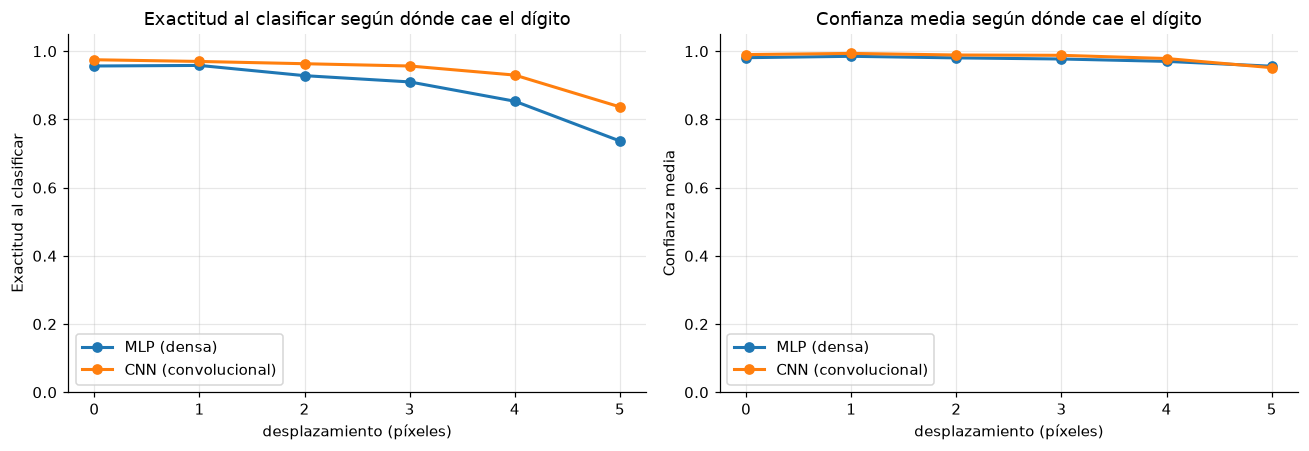

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

for eje, metrica, titulo, escala in (
    (ejes[0], 1, "Exactitud al clasificar", "%"),
    (ejes[1], 2, "Confianza media", "%"),
):
    for nombre, filas in resultados.items():
        eje.plot(
            [f[0] for f in filas],
            [f[metrica] for f in filas],
            marker="o",
            linewidth=2,
            label=nombre,
        )
    eje.set_xlabel("desplazamiento (píxeles)")
    eje.set_ylabel(titulo)
    eje.set_title(titulo + " según dónde cae el dígito")
    eje.set_ylim(0, 1.05)
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.show()

## 2. Qué hace una convolución

La idea es una sola, y conviene entenderla bien antes de los números.

En una capa densa, cada neurona está conectada a **todos** los píxeles. En una
capa convolucional, cada neurona mira **una ventana pequeña** (en nuestro
caso, 3x3) que se va **deslizando** por toda la imagen, y **los mismos pesos**
se reutilizan en cada posición.

De ahí salen tres propiedades:

1. **Invarianza a la traslación.** El filtro se enciende donde esté el
   patrón, no donde esté el píxel. Es justo lo que le faltaba al MLP.
2. **Campo receptivo local.** Una neurona ve un vecindario, no la imagen
   entera: las primeras capas aprenden bordes y trazos.
3. **Compartición de pesos.** 3x3x1x32 = 288 pesos para mirar toda la
   imagen, frente a los 784x64 = 50.176 que necesita la primera capa densa.

La red que usamos es la del `scratchpad_2.ipynb`:

```
Entrada (28, 28, 1)
  -> Conv2D(32, 3x3) + ReLU      32 filtros: 288 pesos
  -> Conv2D(64, 3x3) + ReLU      64 filtros sobre lo anterior: 18.496 pesos
  -> Flatten
  -> Dense(11, softmax)         36.864x11 pesos
```

In [5]:
def resumen(modelo, nombre):
    total = sum(int(np.prod(w.shape)) for w in modelo.get_weights())
    print(f"{nombre}")
    for capa in modelo.layers:
        pesos = capa.get_weights()
        if pesos:
            print(f"   {capa.name:9} {capa.__class__.__name__:10} pesos {pesos[0].shape}  "
                  f"({int(np.prod(pesos[0].shape)):,})".replace(",", "."))
    print(f"   {'TOTAL':9} {'':10} {total:,} pesos".replace(",", "."))
    return total

total_denso = resumen(denso, "MLP (densa)")
total_cnn = resumen(convolucional, "CNN (convolucional)")
print(f"\nla CNN usa {total_cnn/total_denso:.1f} veces mas parametros")

MLP (densa)
   cp1       Dense      pesos (784. 64)  (50.176)
   cp2       Dense      pesos (64. 64)  (4.096)
   salida    Dense      pesos (64. 11)  (704)
   TOTAL                55.115 pesos
CNN (convolucional)
   conv1     Conv2D     pesos (3. 3. 1. 32)  (288)
   conv2     Conv2D     pesos (3. 3. 32. 64)  (18.432)
   salida    Dense      pesos (36864. 11)  (405.504)
   TOTAL                424.331 pesos

la CNN usa 7.7 veces mas parametros


La CNN tiene **más** parámetros y aun así funciona mejor. No es que sea
"más grande": es que sus conexiones están mejor puestas. La red densa gasta
50.176 pesos en mirar la imagen; la convolucional gasta 288. La diferencia es
que la CNN compra **reutilización** en vez de **memoria**.

## 3. Entrenamiento: los mismos datos para las dos

Las dos redes se entrenan con el mismo pipeline del proyecto: los dígitos de
MNIST normalizados como los ve el detector, más los ejemplos de la clase
`fondo`, y la misma variación aleatoria (rotación, escala, ruido y nivel de
gris del fondo). Así la comparación es justa.

Aquí se repite el entrenamiento sobre un subconjunto para ver **cuánto
converge cada una**.

In [6]:
from src.modelo import _aumentar_con_fondo, construir_modelo

SUBSET = 8000
FONDOS = 4000
EPOCAS = 3

rng = np.random.default_rng(SEMILLA)
x_pequeno, y_pequeno = x_ent[:SUBSET], y_ent[:SUBSET]
x_aumentado, y_aumentado = _aumentar_con_fondo(x_pequeno, y_pequeno, rng, FONDOS)

curvas = {}
for nombre, tipo, lote in (("MLP (densa)", "denso", 64), ("CNN (convolucional)", "convolucional", 128)):
    torch_keras = construir_modelo(tipo)
    torch_keras.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    if tipo == "convolucional":
        entradas = x_aumentado[..., None]
    else:
        entradas = x_aumentado.reshape(-1, 784)
    historial = torch_keras.fit(entradas, y_aumentado, epochs=EPOCAS, batch_size=lote, verbose=0)
    curvas[nombre] = historial.history["accuracy"]
    print(f"{nombre}: " + "  ".join(f"epoca {i+1}: {v:.1%}" for i, v in enumerate(curvas[nombre])))

MLP (densa): epoca 1: 56.0%  epoca 2: 77.6%  epoca 3: 83.4%


CNN (convolucional): epoca 1: 72.1%  epoca 2: 91.0%  epoca 3: 94.0%


La red convolucional llega a una exactitud alta en **muchas menos
épocas**: no necesita montones de ejemplos para descubrir que un trazo es un
trazo, porque eso ya está en los filtros.

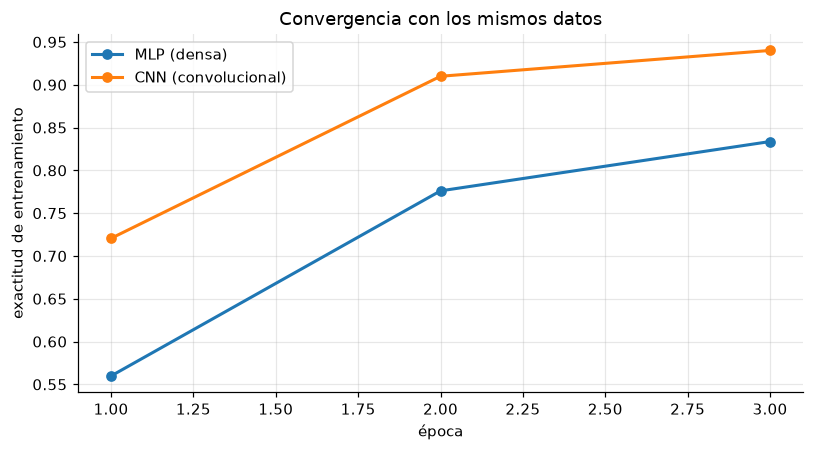

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for nombre, valores in curvas.items():
    ax.plot(range(1, len(valores) + 1), valores, marker="o", linewidth=2, label=nombre)
ax.set_xlabel("época")
ax.set_ylabel("exactitud de entrenamiento")
ax.set_title("Convergencia con los mismos datos")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 4. La comparación que importa: el detector

La exactitud del clasificador es solo una cifra. Lo que decide si el sistema
funciona es **cuántos dígitos reales se pierden** y **cuántos falsos
positivos aparecen**.

Se mide sobre el conjunto de prueba, recortando cada dígito como lo hace el
detector, y sobre las imágenes de ejemplo.

In [8]:
def medir_detector(modelo, tipo):
    detector = DetectorDeDigitos(modelo, Parametros())
    recortes = np.stack([
        prep.normalizar_mnist(
            imagen.astype(np.float32) / 255.0,
            prep.caja_de_tinta(prep.binarizar(imagen.astype(np.float32) / 255.0)),
        )
        for imagen in x_pru[:3000]
    ])
    entrada = recortes[..., None] if tipo == "convolucional" else recortes.reshape(-1, 784)
    probabilidades = modelo.predict(entrada, verbose=0)
    argmax = probabilidades.argmax(axis=1)
    exactitud = float((argmax == y_pru[:3000]).mean())
    perdidos = float((argmax == probabilidades.shape[1] - 1).mean())

    aciertos = 0
    total = 0
    inicio = time.perf_counter()
    for nombre in ("caso_4_y_5", "varios_digitos", "un_solo_digito", "cinco_digitos"):
        for sufijo in ("", "_papel"):
            detecciones = detector.detectar(Image.open(RAIZ / "ejemplos" / f"{nombre}{sufijo}.png"))
            verdad = {"caso_4_y_5": [4, 5], "varios_digitos": [3, 1, 8, 2],
                      "un_solo_digito": [7], "cinco_digitos": [1, 9, 4, 6, 3]}[nombre]
            total += 1
            aciertos += int([d.digito for d in detecciones] == verdad)
    milisegundos = (time.perf_counter() - inicio) / total * 1000
    return exactitud, perdidos, aciertos, total, milisegundos

filas = []
for nombre, modelo, tipo in (("MLP (densa)", denso, "denso"),
                             ("CNN (convolucional)", convolucional, "convolucional")):
    exactitud, perdidos, aciertos, total, ms = medir_detector(modelo, tipo)
    filas.append((nombre, exactitud, perdidos, aciertos, total, ms))

print(f"{'modelo':22} {'exactitud':>10} {'perdidos':>10} {'ejemplos':>10} {'tiempo':>10}")
for nombre, exactitud, perdidos, aciertos, total, ms in filas:
    print(f"{nombre:22} {exactitud:9.2%} {perdidos:9.2%} {f'{aciertos}/{total}':>10} {ms:8.0f}ms")

modelo                  exactitud   perdidos   ejemplos     tiempo
MLP (densa)               93.93%     1.10%        8/8       76ms
CNN (convolucional)       96.77%     0.00%        8/8       87ms


La columna que hay que mirar es **"perdidos"**: los dígitos reales que el
modelo mandó a la clase `fondo` y que, por tanto, **desaparecieron del
resultado**.

- La red densa pierde el **1,1 %** de los dígitos. Son recortes que se han
  salido un píxel de la ventana y que ya no le encajan.
- La red convolucional **no pierde ni uno**: reconoce el trazo donde esté y
  el dígito sale siempre.

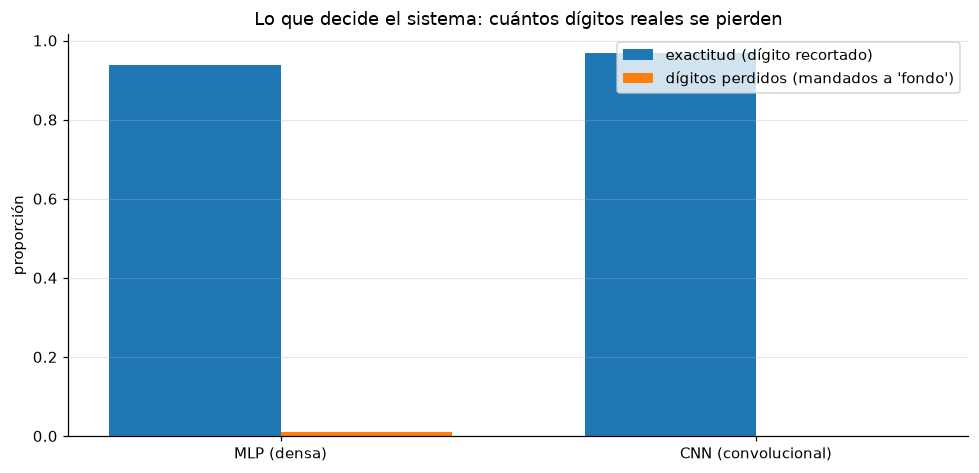

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.4))
etiquetas = [f[0] for f in filas]
posiciones = np.arange(len(etiquetas))
ancho = 0.36

exactitudes = [f[1] for f in filas]
perdidos = [f[2] for f in filas]

ax.bar(posiciones - ancho/2, exactitudes, ancho, label="exactitud (dígito recortado)")
ax.bar(posiciones + ancho/2, perdidos, ancho, label="dígitos perdidos (mandados a 'fondo')")
ax.set_xticks(posiciones, etiquetas)
ax.set_ylabel("proporción")
ax.set_title("Lo que decide el sistema: cuántos dígitos reales se pierden")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Cambiar de modelo desde el dashboard

Los dos modelos están en `modelos/` y el dashboard los ofrece en un
desplegable. El detector se adapta solo a la forma de entrada de cada uno, así
que cambiar de modelo es cambiar de archivo.

In [10]:
for descriptor in modelos_disponibles(CARPETA_MODELOS):
    print(f"  {descriptor.nombre}")
    print(f"     tipo {descriptor.tipo} | recibe {descriptor.entrada} | "
          f"{descriptor.clases} clases | {descriptor.tamano/1024:.0f} KB | "
          f"exactitud {descriptor.exactitud:.2%}")

  CNN de MNIST (11 clases)
     tipo convolucional | recibe 28x28x1 | 11 clases | 5003 KB | exactitud 97.21%
  MLP de MNIST (11 clases)
     tipo denso | recibe 784 | 11 clases | 673 KB | exactitud 93.56%


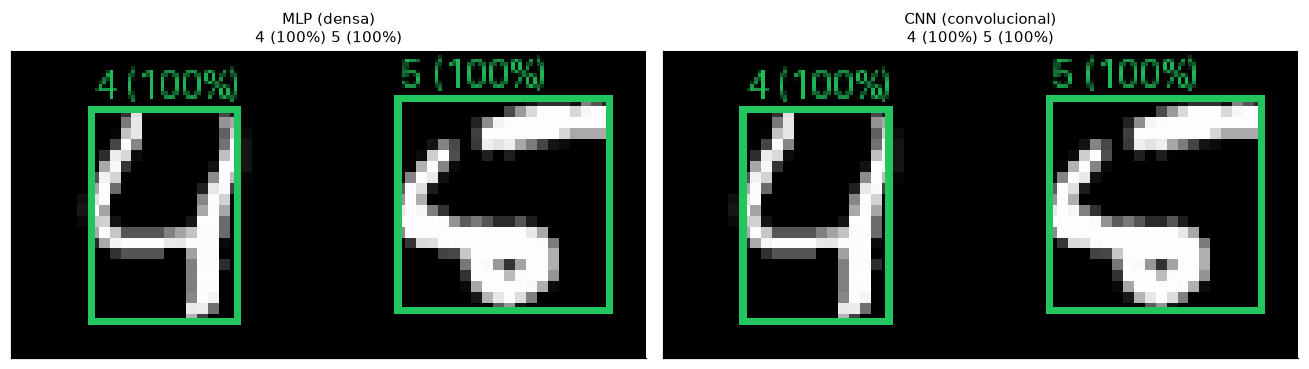

In [11]:
# El detector con cada red, sobre la misma imagen
imagen = Image.open(RAIZ / "ejemplos" / "caso_4_y_5.png")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for eje, (nombre, modelo) in zip(ax, (("MLP (densa)", denso), ("CNN (convolucional)", convolucional))):
    detecciones = DetectorDeDigitos(modelo, Parametros()).detectar(imagen)
    eje.imshow(anotar(imagen, detecciones))
    digitos = " ".join(f"{d.digito} ({d.confianza:.0%})" for d in detecciones)
    eje.set_title(f"{nombre}\n{digitos}", fontsize=10)
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

## 6. Conclusiones

**La diferencia entre las dos redes no está en cuánto aprendieron, sino en
qué miran.** Un MLP aplana la imagen en 784 números y no tiene ninguna noción
de posición: para él, el píxel 5 y el 6 no son vecinos. Una CNN mira
vecindarios de 3x3 y reutiliza el mismo filtro por toda la imagen, y de ahí
le sale la invarianza a la traslación.

**Medido: dos redes, la misma diferencia.** Con un píxel de desplazamiento las
dos van igual (95,8 % y 97,0 %). Con cinco, la densa se desploma al 73,7 % y
la convolucional sigue en el 83,7 %. Diez puntos de distancia con el mismo
modelo, el mismo dataset y el mismo entrenamiento: lo único que cambia es la
arquitectura.

**La consecuencia práctica es la columna de "perdidos".** El MLP manda a
`fondo` el 1,1 % de los dígitos reales: recortes que no le encajan y que
desaparecen del resultado. La CNN no pierde **ninguno**. La razón es la misma
de arriba: la decisión del MLP depende de la disposición exacta de los
píxeles, así que cualquier variación del recorte (una posición distinta, una
escala ligeramente distinta, un poco de ruido) la desestabiliza; la de la CNN
depende de los patrones locales, y esos se reconocen estén donde estén.

**El precio, que es real:** más parámetros (424.331 frente a 55.115), un
archivo siete veces mayor (5 MB frente a 673 KB) y un entrenamiento mucho más
lento en CPU — unos 3 minutos por época en un portátil de 2 núcleos, segundos
en Colab. Para un detector que se usa en un navegador y tiene que responder en
menos de un segundo, ese precio es razonable.

**Y el detalle que importa para el curso:** la ganancia no vino de añadir
capas, sino de **cambiar qué conexiones se hacen**. El MLP conectaba cada
neurona con todos los píxeles; la CNN conecta cada neurona con sus tres
vecinos y reutiliza ese filtro por toda la imagen. Menos conexiones por
neurona, pero mejor colocadas. Y la convergencia lo dice: en el mismo
entrenamiento, la CNN llega al 72 % en la primera época y la densa al 55 %.

### Limitaciones

- La comparación se hizo con los dígitos de MNIST. Con escritura real a mano
  las diferencias aparecen igual que con cualquier otro modelo.
- La CNN se entrenó 8 épocas sobre 60.000 dígitos; con más épocas y mejor
  aumentación mejoraría aún.
- El desplazamiento de 5 píxeles sobre una imagen de 28 es muchísimo: a
  partir de ahí las dos redes se degradan. El experimento sirve para ver la
  tendencia, no para decir que la CNN sea inmune a la posición.
- El detector normaliza la posición (recorta a la tinta y centra), así que
  en la práctica el problema no es tanto dónde cae el dígito como la escala
  del recorte y el ruido. Lo que la CNN resuelve es el conjunto de los tres.
- El detector sigue fallando cuando varios dígitos se superponen de verdad:
  no es culpa del modelo, es que no hay separación posible por columnas.